# EDA - SEER Breast Cancer Dataset


In [1]:
import gdown
import os
import pandas as pd
import numpy as np
file_id = '11v9wGSrAL3WY_pfIehGL5mVOvTBXGiIh'

url = f'https://drive.google.com/uc?id={file_id}'

output_file = 'Breast_Cancer.csv'
gdown.download(url, output_file, quiet=False, fuzzy=True)
df = pd.read_csv(output_file)

print("Data loaded successfully. Shape:", df.shape)

Downloading...
From: https://drive.google.com/uc?id=11v9wGSrAL3WY_pfIehGL5mVOvTBXGiIh
To: /content/Breast_Cancer.csv
100%|██████████| 15.0M/15.0M [00:00<00:00, 55.8MB/s]


Data loaded successfully. Shape: (100000, 17)


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set default Seaborn theme for better aesthetics
sns.set_theme(style="whitegrid", palette="Set2")
print("Libraries imported successfully!")

Libraries imported successfully!


### Load data and check overview

In [3]:
# Read CSV file
drive_file_path = '/content/drive/MyDrive/N33/04 Datasets/Breast_Cancer.csv'
local_file = 'Breast_Cancer.csv'

if os.path.exists(drive_file_path):
    dataset = drive_file_path
    print(f"File loaded directly from Google Drive: {dataset}")
else:
    dataset = local_file
    if not os.path.exists(local_file):
        file_id = '11v9wGSrAL3WY_pfIehGL5mVOvTBXGiIh'
        url = f'https://drive.google.com/uc?id={file_id}'
        gdown.download(url, local_file, quiet=False)
    print("File loaded from Colab temporary storage via gdown.")

df = pd.read_csv(dataset)
df['Age'] = df['Age'].astype(str).str.extract(r'(\d+)').astype(float)
df['Survival months'] = pd.to_numeric(df['Survival months'], errors='coerce')
df['Tumor Size'] = pd.to_numeric(df['Tumor Size'], errors='coerce')
df['Regional Nodes Examined'] = pd.to_numeric(df['Regional Nodes Examined'], errors='coerce')
df['Regional Nodes Positive'] = pd.to_numeric(df['Regional Nodes Positive'], errors='coerce')
df.loc[df['Tumor Size'] >= 990, 'Tumor Size'] = np.nan
df.loc[df['Regional Nodes Examined'] >= 90, 'Regional Nodes Examined'] = np.nan
df.loc[df['Regional Nodes Positive'] >= 90, 'Regional Nodes Positive'] = np.nan
# Display first 5 rows
display(df.head())

# Print general information (columns, rows, data types, missing values)
print("\n--- General Information ---")
df.info()

# Check for missing values
print("\n--- Missing Values Check ---")
print(df.isnull().sum())

File loaded from Colab temporary storage via gdown.


,Patient ID,Marital status at diagnosis,Sequence number,Survival months,Age,Race,T Stage,N Stage,Grade,6th Stage,Tumor Size,Regional Nodes Positive,Regional Nodes Examined,Progesterone Status,Estrogen Status,A Stage,Status
0,26486040,Widowed,2nd of 2 or more primaries,110.0,86.0,Non-Hispanic White,Blank(s),Blank(s),III,Blank(s),NaN,5.0,16.0,Positive,Positive,Regional,Dead
1,36240463,Married (including common law),One primary only,79.0,45.0,Non-Hispanic Asian or Pacific Islander,Blank(s),Blank(s),III,Blank(s),NaN,0.0,3.0,Negative,Negative,Blank(s),Alive
2,11042019,Divorced,One primary only,140.0,49.0,Non-Hispanic White,T2,N0(i-),II,IIA,25.0,0.0,3.0,Positive,Positive,Localized,Alive
3,46550420,Married (including common law),One primary only,105.0,65.0,Non-Hispanic White,T1a,N0,I,I,5.0,NaN,0.0,Positive,Positive,Localized,Dead
4,21881624,Widowed,2nd of 2 or more primaries,0.0,86.0,Non-Hispanic Black,TX,NX,Unknown,UNK Stage,NaN,NaN,0.0,Borderline/Unknown,Borderline/Unknown,Unstaged,Dead



--- General Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 17 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Patient ID                   100000 non-null  int64  
 1   Marital status at diagnosis  100000 non-null  object 
 2   Sequence number              100000 non-null  object 
 3   Survival months              99612 non-null   float64
 4   Age                          100000 non-null  float64
 5   Race                         100000 non-null  object 
 6   T Stage                      99924 non-null   object 
 7   N Stage                      99924 non-null   object 
 8   Grade                        100000 non-null  object 
 9   6th Stage                    99924 non-null   object 
 10  Tumor Size                   46394 non-null   float64
 11  Regional Nodes Positive      81843 non-null   float64
 12  Regional Nodes Examined      9

In [4]:
print(f"Tổng số mẫu dữ liệu trong tập dữ liệu là: {df.shape[0]:,}")

Tổng số mẫu dữ liệu trong tập dữ liệu là: 100,000


In [5]:
# Kiểm tra số lượng dòng trùng lặp hoàn toàn (trùng tất cả các cột)
num_duplicates = df.duplicated().sum()
print(f"Số lượng mẫu dữ liệu bị trùng lặp hoàn toàn: {num_duplicates}")

# Nếu có trùng lặp, hiển thị tỷ lệ phần trăm
if num_duplicates > 0:
    print(f"Tỷ lệ dữ liệu trùng lặp: {(num_duplicates / len(df)) * 100:.4f}%")

Số lượng mẫu dữ liệu bị trùng lặp hoàn toàn: 0


### Numerical Features Distribution

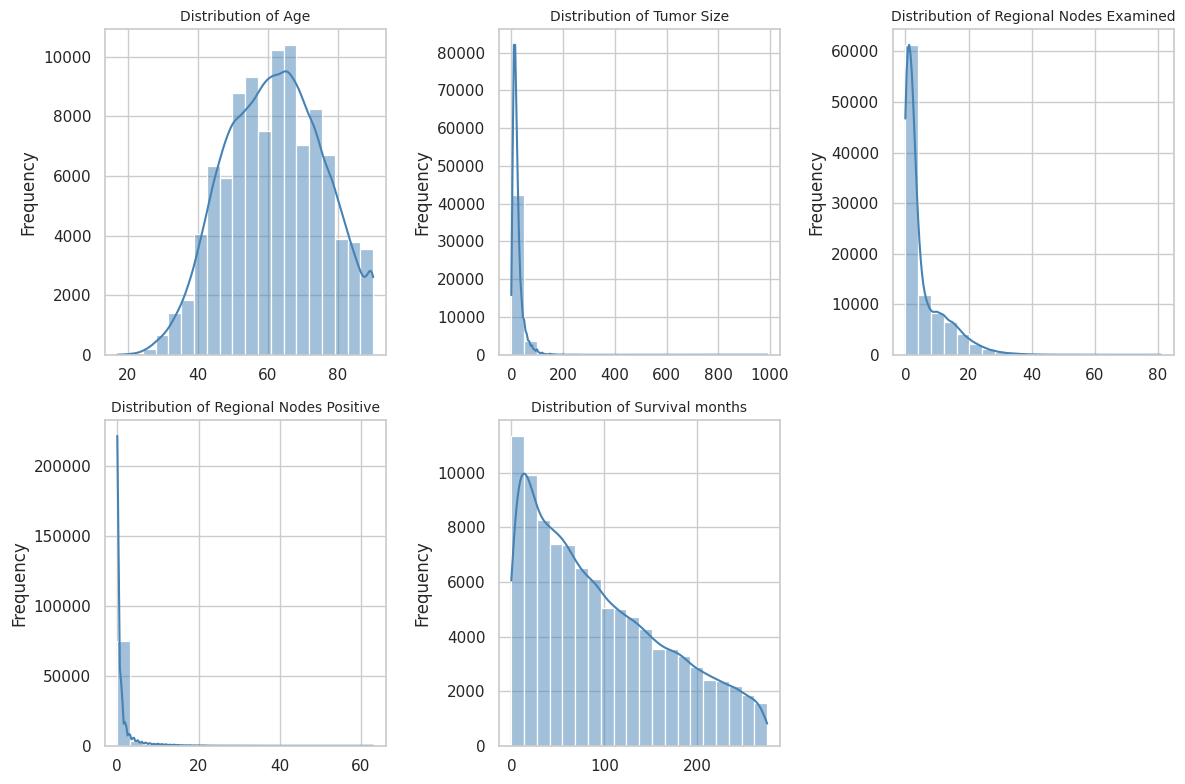

In [6]:
num_cols = ['Age', 'Tumor Size', 'Regional Nodes Examined', 'Regional Nodes Positive', 'Survival months']

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data=df.dropna(subset=[col]), x=col, kde=True, ax=axes[i], color='steelblue', bins=20)
    axes[i].set_title(f'Distribution of {col}', fontsize=10)
    axes[i].set_ylabel('Frequency')
    axes[i].set_xlabel('')

fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

### Target Variable Distribution


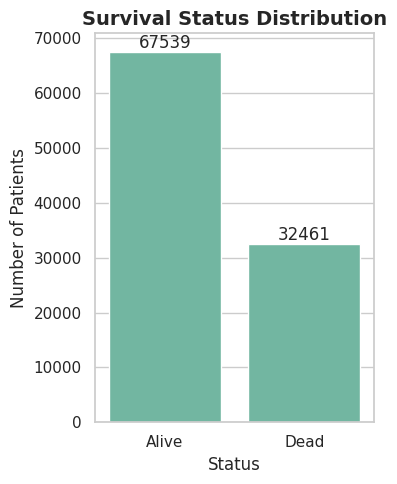

In [7]:
plt.figure(figsize=(4, 5))
ax = sns.countplot(data=df, x='Status', order=['Alive', 'Dead'])

plt.title('Survival Status Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Status', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=12)

plt.tight_layout()
plt.show()

### Numerical Features Distribution


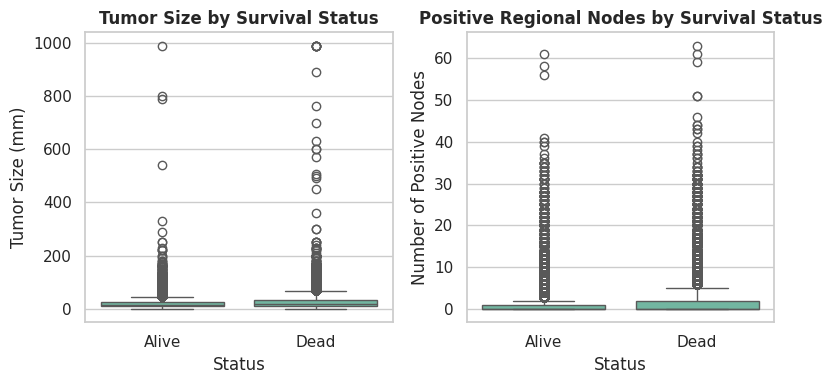

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Chart Tumor Size
sns.boxplot(data=df, x='Status', y='Tumor Size', order=['Alive', 'Dead'], ax=axes[0])
axes[0].set_title('Tumor Size by Survival Status', fontweight='bold')
axes[0].set_ylabel('Tumor Size (mm)')

# Chart Regional Node Positive
sns.boxplot(data=df, x='Status', y='Regional Nodes Positive', order=['Alive', 'Dead'], ax=axes[1])
axes[1].set_title('Positive Regional Nodes by Survival Status', fontweight='bold')
axes[1].set_ylabel('Number of Positive Nodes')

plt.tight_layout()
plt.show()

### Categorical Features Distribution
Corresponds to Slide 11: Impact of tumor grade on mortality.

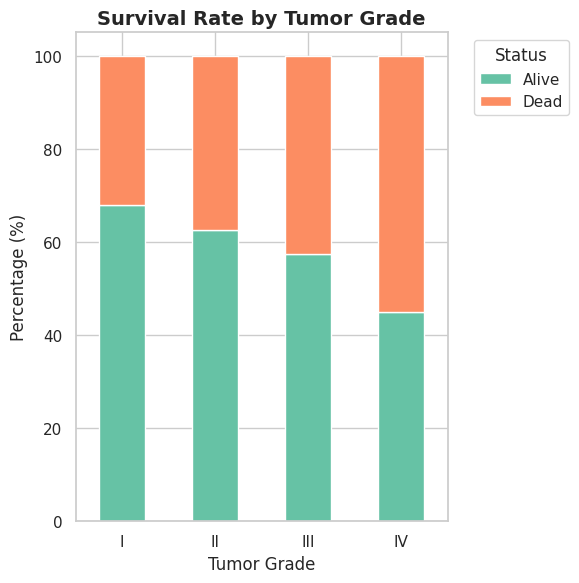

In [9]:
# Calculate cross-tabulation as percentages
df_filtered=df[~df['Grade'].isin(['Blank(s)', 'Unknown'])]
grade_status = pd.crosstab(df_filtered['Grade'], df_filtered['Status'], normalize='index') * 100

# Plot stacked bar chart using pandas, with seaborn colors
grade_status.plot(kind='bar', stacked=True, color=['#66c2a5', '#fc8d62'], figsize=(6,6))

plt.title('Survival Rate by Tumor Grade', fontsize=14, fontweight='bold')
plt.xlabel('Tumor Grade', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.legend(title='Status', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Correlation Heatmap
Added block to find highly correlated numerical variables.

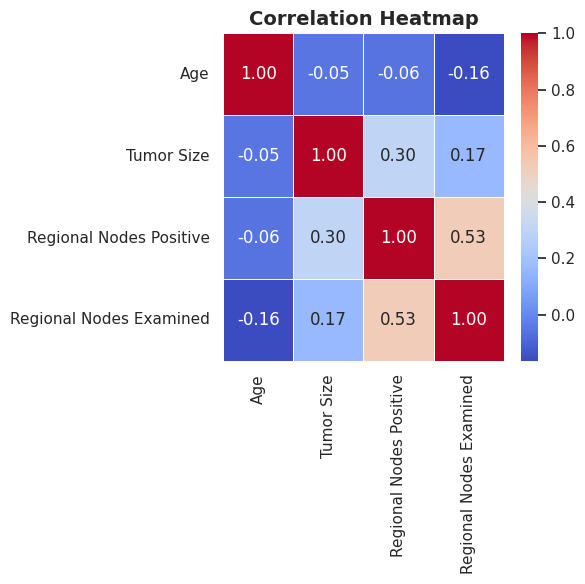

In [10]:
plt.figure(figsize=(6, 6))

# Select only numerical columns for correlation calculation
drop_cols=['Patient ID', 'Survival months']
df_features=df.drop(columns=[col for col in drop_cols if col in df.columns])
numeric_df = df_features.select_dtypes(include=['int64', 'float64'])
corr_matrix = numeric_df.corr()

# Plot Heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

plt.title('Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

```markdown
## 1. Khám Phá Tổng Quan, Định Danh Và Sequence Number
Chúng ta tiến hành đánh giá chi tiết tính định danh của bệnh nhân, phân tích tần suất số thứ tự khối u (`Sequence number`) để hiểu về tỷ lệ đa u nguyên phát (multiple primaries) - một yếu tố tiên lượng cực kỳ quan trọng trong ung thư học, đồng thời thống kê toàn diện các dạng giá trị thiếu đặc thù của hệ thống mã hóa SEER.
```

In [11]:
# 1. Đếm số lượng bệnh nhân duy nhất
total_rows = len(df)
unique_patients = df['Patient ID'].nunique()
print(f"Tổng số dòng dữ liệu: {total_rows:,}")
print(f"Số lượng bệnh nhân duy nhất (Patient ID): {unique_patients:,}")
print(f"Trung bình số bản ghi trên mỗi bệnh nhân: {total_rows / unique_patients:.2f}\n")

# 2. Phân tích phân bố Sequence number
# Quy đổi Sequence number về dạng tường minh để dễ phân tích
print("--- Phân Bố Tần Suất Sequence Number ---")
seq_counts = df['Sequence number'].value_counts()
seq_pct = df['Sequence number'].value_counts(normalize=True) * 100
seq_summary = pd.DataFrame({'Số lượng': seq_counts, 'Tỷ lệ (%)': seq_pct})
display(seq_summary)

# 3. Kiểm tra các mã quy ước SEER biểu thị giá trị thiếu ẩn
print("\n--- Thống Kê Các Mã Quy Ước Thiếu / Không Rõ (SEER Special Codes) ---")

seer_missing_codes = ['Blank(s)', 'Unknown', 'UNK Stage', 'TX', 'NX', 'OCCULT', 'NA']
missing_report = []

# Kiểm tra trên toàn bộ các cột kiểu Object
for col in df.select_dtypes(include=['object']).columns:
    for code in seer_missing_codes:
        cnt = (df[col].astype(str).str.strip() == code).sum()
        if cnt > 0:
            missing_report.append({
                'Cột': col,
                'Loại giá trị thiếu': code,
                'Số lượng': cnt,
                'Tỷ lệ (%)': (cnt / total_rows) * 100
            })

# Thêm kiểm tra mã số đặc thù SEER (mã hóa ngoại lệ)
# Tumor Size >= 990 thường là mô tả hạch hoặc không đo được bằng mm thực tế
num_missing_specs = [
    ('Tumor Size', 990, "Mã >= 990 (Microscopic/Unknown size)"),
    ('Regional Nodes Examined', 90, "Mã >= 90 (Unknown/Not examined)"),
    ('Regional Nodes Positive', 90, "Mã >= 90 (Unknown/Positive nodes codes)")
]

for col, threshold, desc in num_missing_specs:
    cnt = (df[col] >= threshold).sum() # Số lượng trước khi chúng ta gán NaN ở bước trước hoặc nếu còn sót
    # Lưu ý: Ở cell trước bạn đã gán np.nan cho các giá trị này. Hãy đếm số lượng NaN hiện tại trên cột này làm đại diện cho thiếu hụt
    nan_cnt = df[col].isnull().sum()
    missing_report.append({
        'Cột': col,
        'Loại giá trị thiếu': f"NaN (Gồm cả các mã lỗi hệ thống {threshold}+)",
        'Số lượng': nan_cnt,
        'Tỷ lệ (%)': (nan_cnt / total_rows) * 100
    })

df_missing_report = pd.DataFrame(missing_report)
display(df_missing_report.sort_values(by='Tỷ lệ (%)', ascending=False))

Tổng số dòng dữ liệu: 100,000
Số lượng bệnh nhân duy nhất (Patient ID): 99,447
Trung bình số bản ghi trên mỗi bệnh nhân: 1.01

--- Phân Bố Tần Suất Sequence Number ---


,Số lượng,Tỷ lệ (%)
Sequence number,,
One primary only,69143,69.143
2nd of 2 or more primaries,15236,15.236
1st of 2 or more primaries,12821,12.821
3rd of 3 or more primaries,2340,2.340
4th of 4 or more primaries,379,0.379
5th of 5 or more primaries,67,0.067
6th of 6 or more primaries,11,0.011
7th of 7 or more primaries,2,0.002
9th of 9 or more primaries,1,0.001



--- Thống Kê Các Mã Quy Ước Thiếu / Không Rõ (SEER Special Codes) ---


,Cột,Loại giá trị thiếu,Số lượng,Tỷ lệ (%)
10,Tumor Size,NaN (Gồm cả các mã lỗi hệ thống 990+),53606,53.606
3,N Stage,Blank(s),49883,49.883
1,T Stage,Blank(s),49883,49.883
7,6th Stage,Blank(s),49883,49.883
9,A Stage,Blank(s),34002,34.002
5,Grade,Blank(s),24521,24.521
12,Regional Nodes Positive,NaN (Gồm cả các mã lỗi hệ thống 90+),18157,18.157
6,Grade,Unknown,7678,7.678
0,Marital status at diagnosis,Unknown,4577,4.577
11,Regional Nodes Examined,NaN (Gồm cả các mã lỗi hệ thống 90+),4010,4.010


```markdown
## 2. Cảnh Báo Rò Rỉ Mục Tiêu (Target Leakage) & Phân Bố Nhãn

### Phân tích mối quan hệ giữa `Survival months` và `Status`
Trong các bài toán dự đoán lâm sàng tại thời điểm chẩn đoán ban đầu (baseline prediction), mục tiêu là hỗ trợ bác sĩ đưa ra quyết định phác đồ điều trị ngay từ đầu. Một sai lầm phổ biến là đưa biến số thời gian sống thêm (`Survival months`) vào mô hình dự báo tình trạng sống/chết (`Status`). Chúng ta sẽ trực quan hóa mối quan hệ này để chỉ ra nguy cơ rò rỉ thông tin mục tiêu.

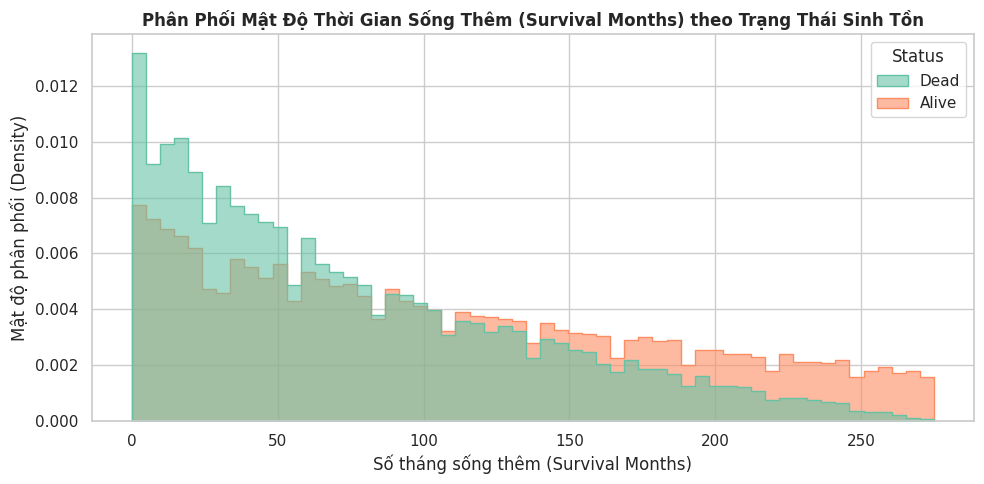

,count,mean,std,min,25%,50%,75%,max
Status,,,,,,,,
Alive,67539.0,105.690238,76.007235,0.0,40.0,92.0,163.0,275.0
Dead,32073.0,75.401896,61.527757,0.0,25.0,60.0,115.0,274.0


In [12]:
# Trực quan hóa mối quan hệ giữa Survival months và Status
plt.figure(figsize=(10, 5))
sns.histplot(data=df.dropna(subset=['Survival months']), x='Survival months', hue='Status',
             element='step', stat='density', common_norm=False, palette='Set2', alpha=0.6)
plt.title('Phân Phối Mật Độ Thời Gian Sống Thêm (Survival Months) theo Trạng Thái Sinh Tồn', fontsize=12, fontweight='bold')
plt.xlabel('Số tháng sống thêm (Survival Months)')
plt.ylabel('Mật độ phân phối (Density)')
plt.tight_layout()
plt.show()

# Thống kê mô tả Survival months theo nhóm Status
display(df.groupby('Status')['Survival months'].describe())

```markdown
> ⚠️ **CẢNH BÁO LÂM SÀNG - TARGET LEAKAGE**
>
> Biến `Survival months` ghi nhận tổng thời gian theo dõi của bệnh nhân cho đến khi họ qua đời hoặc kết thúc nghiên cứu. Đây là thông tin **sau thời điểm chẩn đoán ban đầu (T0)**.
>
> Nhìn vào biểu đồ phân bố, những bệnh nhân có số tháng theo dõi rất ngắn có tỷ lệ tử vong cao vượt trội, trong khi nhóm sống sót tập trung ở dải thời gian theo dõi dài hơn. Nếu đưa `Survival months` vào mô hình dự đoán `Status` lúc chẩn đoán ban đầu, mô hình sẽ bị **rò rỉ mục tiêu cực kỳ nghiêm trọng** (vì hệ thống thu thập dữ liệu này hồi cứu sau khi kết cục đã xảy ra). Do đó, **bắt buộc phải loại bỏ** `Survival months` khi huấn luyện mô hình dự báo lâm sàng hỗ trợ ra quyết định tại thời điểm chẩn đoán ban đầu.
```

```markdown
## 3. Trực Quan Hóa Đặc Trưng Lâm Sàng Phái Sinh & Phân Tích Chuyên Sâu

### Tạo chỉ số lâm sàng phái sinh `Positive_Node_Ratio`
Tỷ lệ hạch dương tính trên tổng số hạch được sinh thiết/khảo sát (`Positive_Node_Ratio = Regional Nodes Positive / Regional Nodes Examined`) là một chỉ số lâm sàng mạnh mẽ phản ánh mức độ xâm lấn vùng của tế bào ung thư hơn là chỉ sử dụng số lượng hạch tuyệt đối đơn thuần.

In [13]:
# Tạo biến lâm sàng phái sinh Positive_Node_Ratio
df['Positive_Node_Ratio'] = np.where(
    (df['Regional Nodes Examined'] > 0) & (df['Regional Nodes Examined'].notnull()) & (df['Regional Nodes Positive'].notnull()),
    df['Regional Nodes Positive'] / df['Regional Nodes Examined'],
    0.0
)

# Đảm bảo giới hạn tỷ lệ nằm trong khoảng [0, 1]
df['Positive_Node_Ratio'] = df['Positive_Node_Ratio'].clip(0.0, 1.0)

print("Thông tin thống kê mô tả chỉ số lâm sàng phái sinh mới:")
display(df['Positive_Node_Ratio'].describe())

Thông tin thống kê mô tả chỉ số lâm sàng phái sinh mới:


,Positive_Node_Ratio
count,100000.000000
mean,0.097677
std,0.231039
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,1.000000


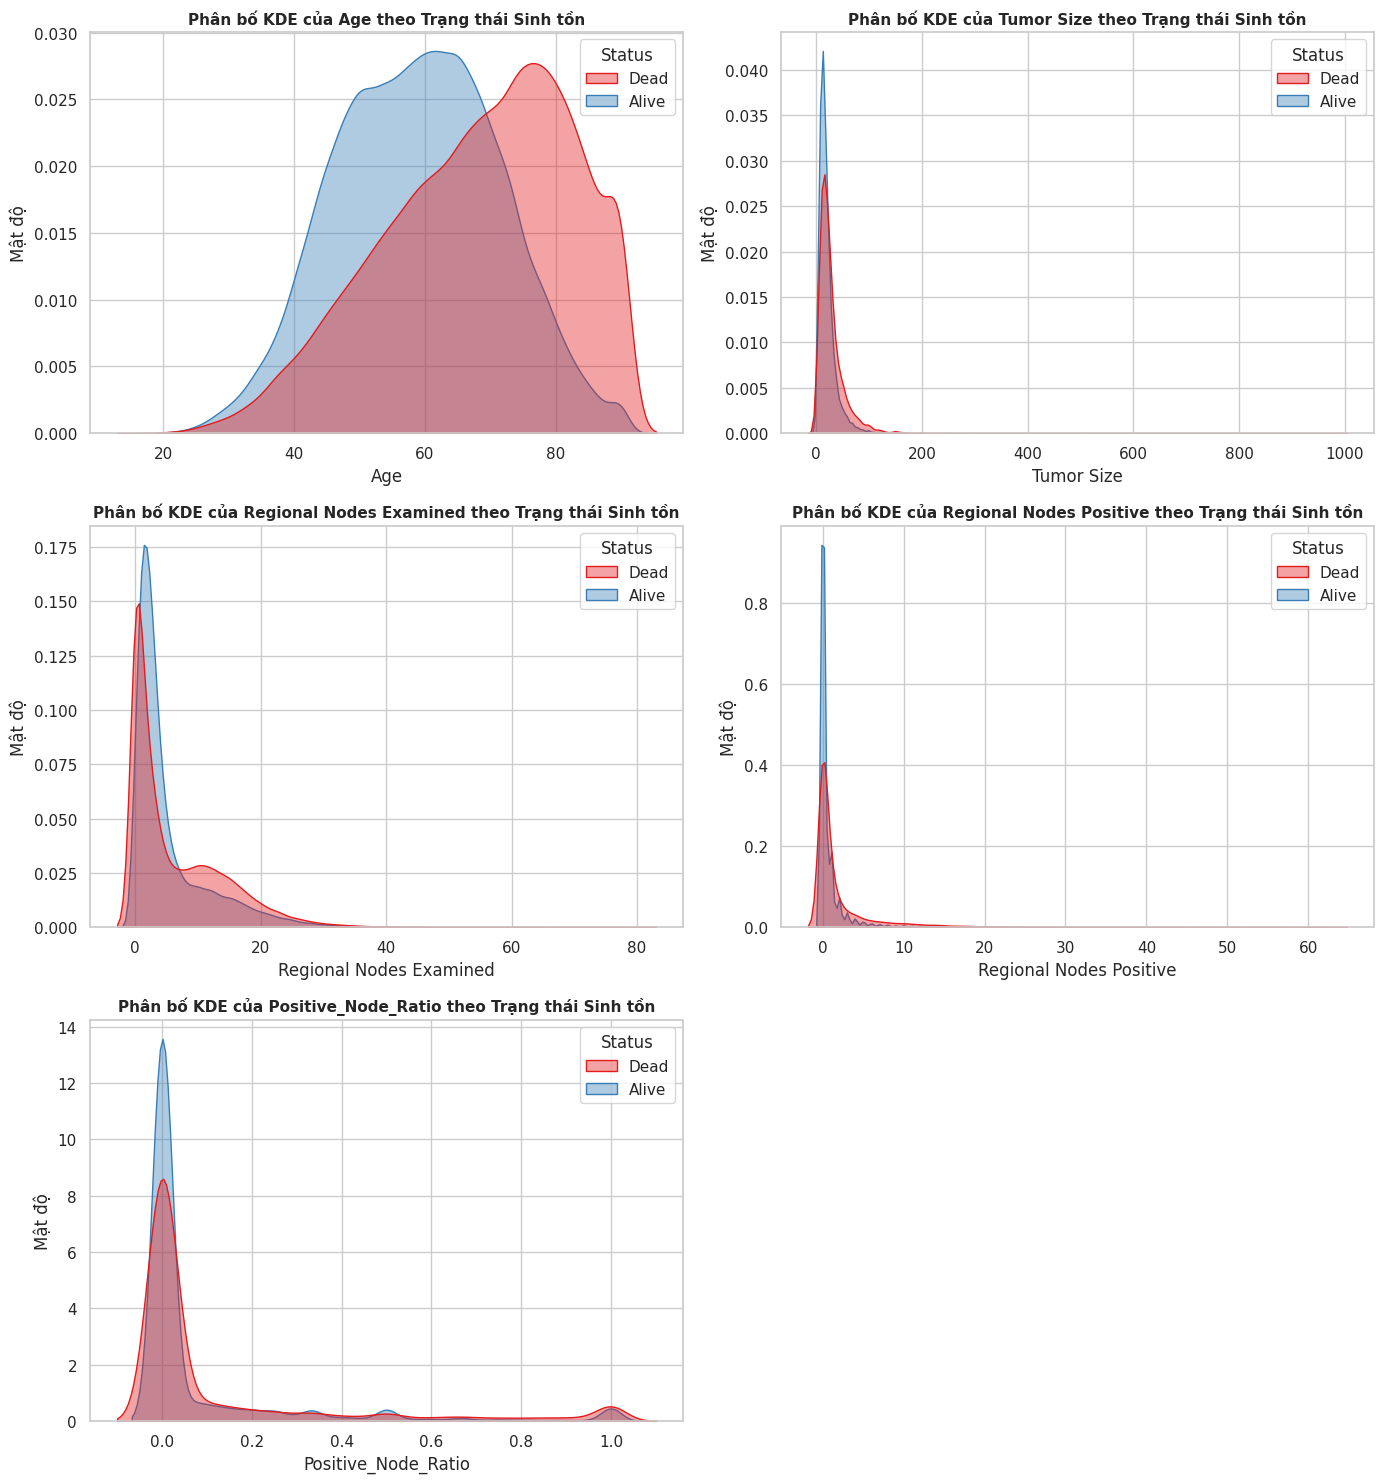

In [14]:
# Phân bố các biến liên tục quan trọng
continuous_vars = ['Age', 'Tumor Size', 'Regional Nodes Examined', 'Regional Nodes Positive', 'Positive_Node_Ratio']

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for i, col in enumerate(continuous_vars):
    sns.kdeplot(data=df, x=col, hue='Status', fill=True, ax=axes[i], palette='Set1', common_norm=False, alpha=0.4)
    axes[i].set_title(f'Phân bố KDE của {col} theo Trạng thái Sinh tồn', fontsize=11, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Mật độ')

# Ẩn subplot thừa cuối cùng
fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

```markdown
### Ảnh Hưởng Của Các Đặc Trưng Phân Loại Đến Tỷ Lệ Tử Vong
Chúng ta xây dựng các biểu đồ Stacked Bar Chart biểu thị tỷ lệ phần trăm phân bố trạng thái `Alive` và `Dead` trên từng phân nhóm của `Grade`, `T Stage`, `Sequence number`, và tình trạng thụ thể nội tiết (`Estrogen Status`, `Progesterone Status`).
```

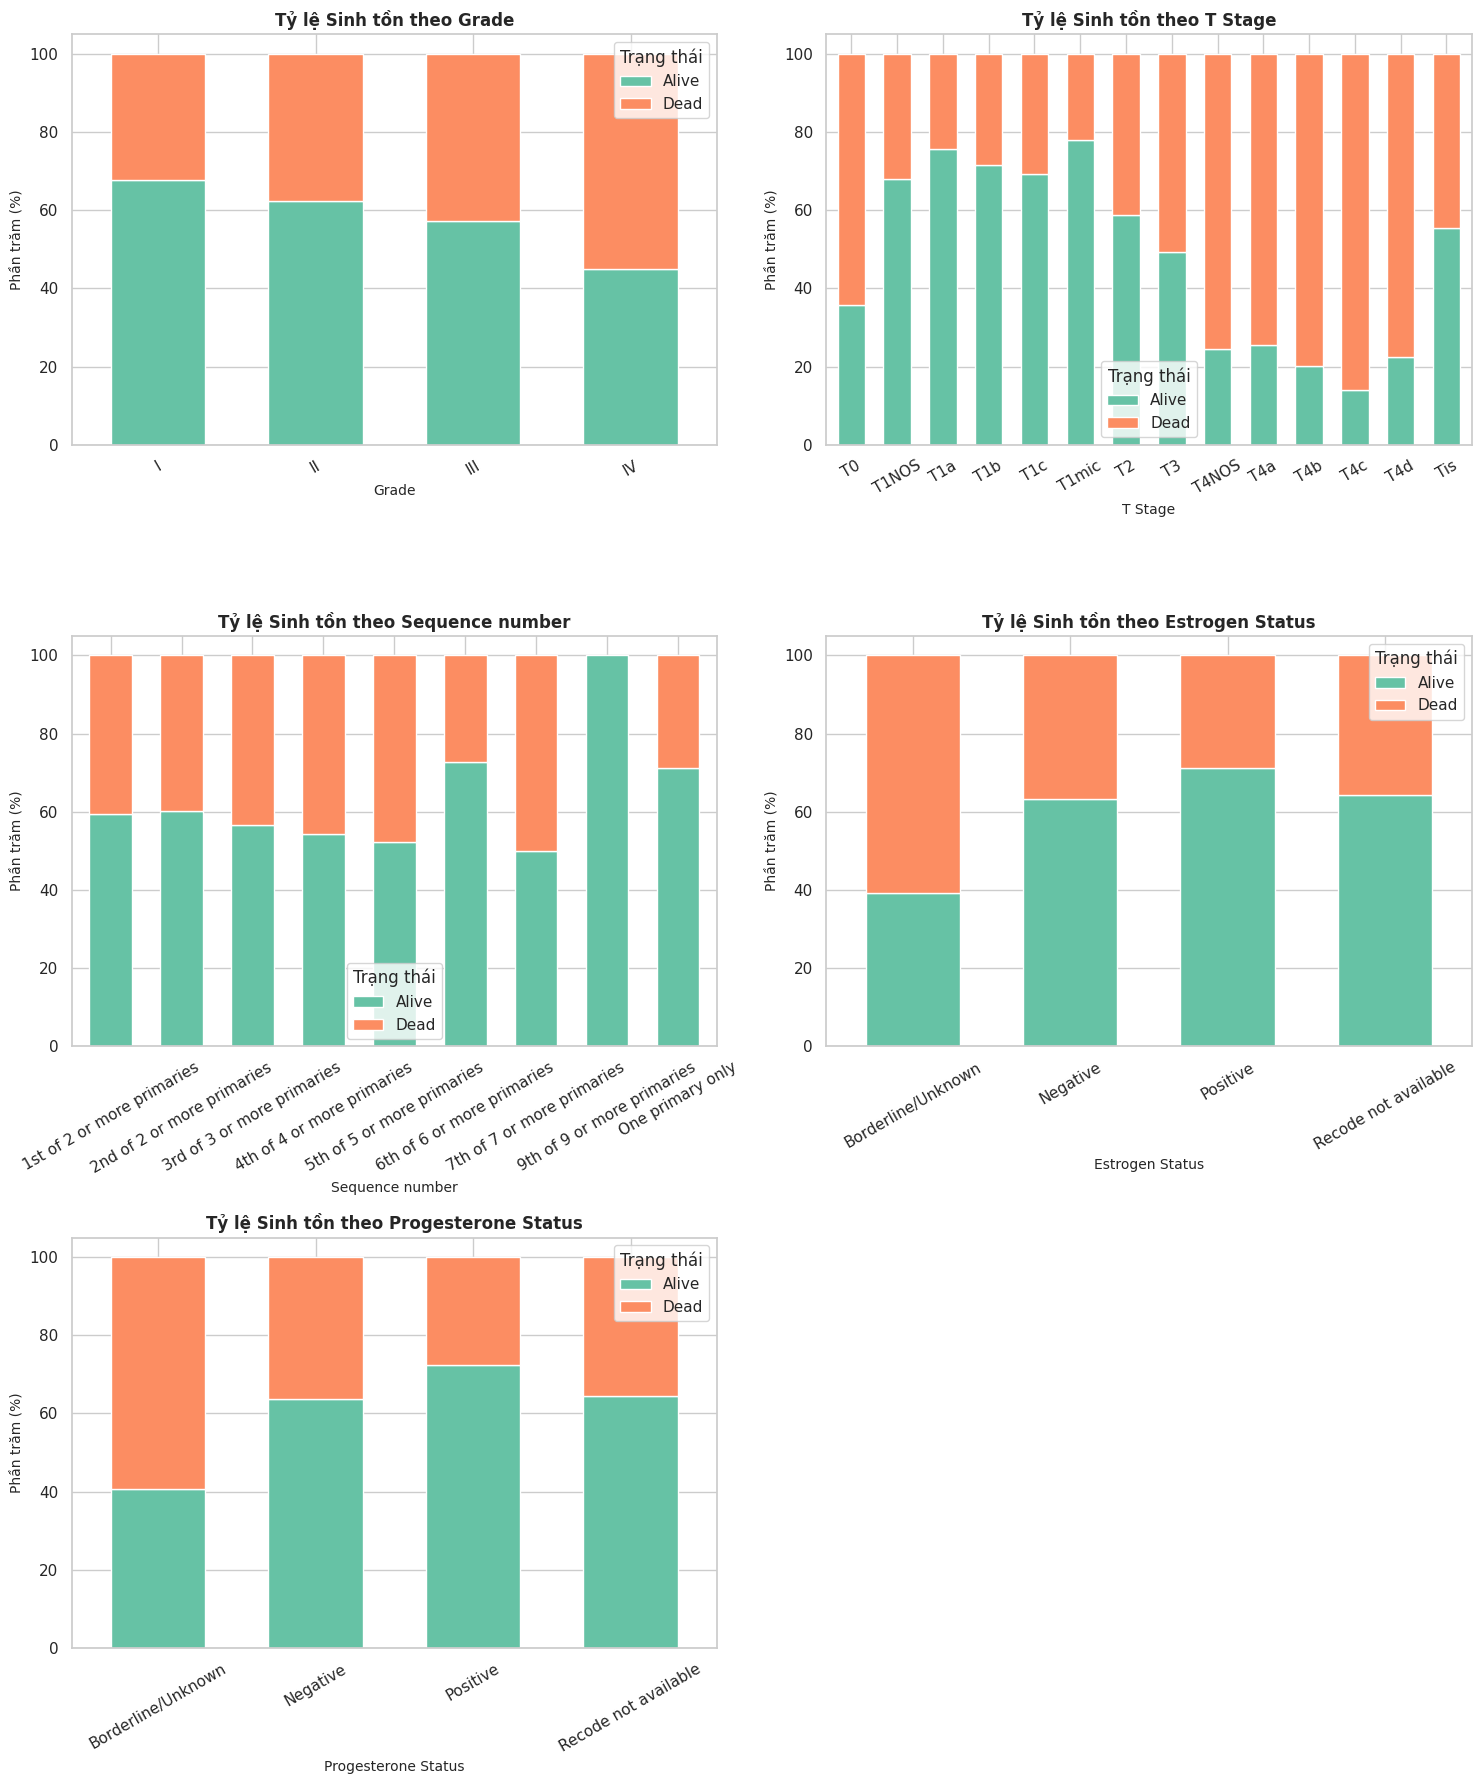

In [15]:
categorical_cols = ['Grade', 'T Stage', 'Sequence number', 'Estrogen Status', 'Progesterone Status']

fig, axes = plt.subplots(3, 2, figsize=(15, 18))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    # Lọc bỏ các giá trị không hợp lệ để biểu đồ trực quan chính xác nhất
    df_temp = df[~df[col].astype(str).str.strip().isin(['Blank(s)', 'Unknown', 'UNK Stage', 'TX', 'NX', 'OCCULT', 'NA', 'nan'])]

    # Tính toán bảng chéo tỷ lệ %
    crosstab_res = pd.crosstab(df_temp[col], df_temp['Status'], normalize='index') * 100

    # Vẽ stacked bar
    crosstab_res.plot(kind='bar', stacked=True, color=['#66c2a5', '#fc8d62'], ax=axes[i], width=0.6)
    axes[i].set_title(f'Tỷ lệ Sinh tồn theo {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Phần trăm (%)', fontsize=10)
    axes[i].legend(title='Trạng thái')
    axes[i].tick_params(axis='x', rotation=30)

fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

```markdown
### Heatmap Tương Quan Toàn Diện Giữa Các Biến Liên Tục (Bao gồm Chỉ số lâm sàng phái sinh mới)
```

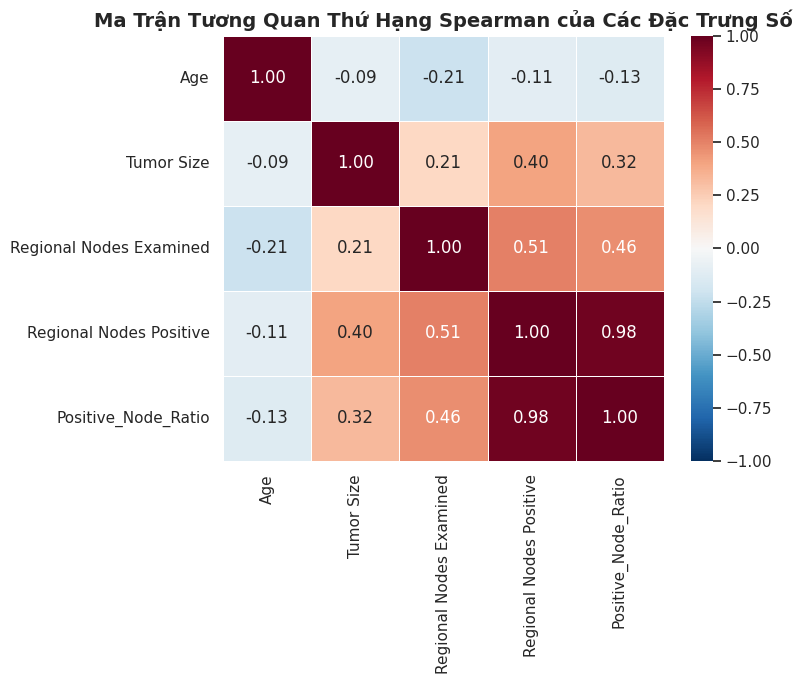

In [16]:
plt.figure(figsize=(8, 7))

# Độc lập hoàn toàn với Survival months và Patient ID
numerical_cols = ['Age', 'Tumor Size', 'Regional Nodes Examined', 'Regional Nodes Positive', 'Positive_Node_Ratio']
corr_matrix = df[numerical_cols].corr(method='spearman')  # Sử dụng Spearman vì phân phối lệch nhiều

sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Ma Trận Tương Quan Thứ Hạng Spearman của Các Đặc Trưng Số', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()